In [2]:
#from libpysal.weights.contiguity import Queen #, higher_order
from libpysal.weights import higher_order, Queen
from splot.esda import plot_local_autocorrelation, lisa_cluster
from esda.moran import Moran_Local_BV, Moran_Local

from matplotlib import pyplot as plt

import geopandas as gpd
import pandas as pd
import h3pandas
import numpy as np

In [3]:
sp = gpd.read_file("../data/sp.geojson")

In [4]:
housing13 = pd.read_csv(f"../data/address/origins__2013.csv", sep=';')
housing13 = housing13.groupby("h3_09").agg({"N_HOUSING": 'sum'}).reset_index()
housing22 = pd.read_csv(f"../data/address/origins__2022.csv", sep=';')
housing22 = housing22.groupby("h3_09").agg({"N_HOUSING": 'sum'}).reset_index()
housing = housing13.merge(housing22, on="h3_09", suffixes=["___13", "___22"])
del housing13
del housing22
housing = housing.set_index("h3_09")
housing = housing.h3.h3_to_geo_boundary()
housing["delta_housing"] = housing.N_HOUSING___22 - housing.N_HOUSING___13


In [5]:
wHousing = Queen.from_dataframe(housing)
wHousing2 = higher_order(wHousing, k=2, lower_order=True)

wHousing.transform = 'r'
wHousing2.transform = 'r'

/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_8273/3988209364.py:1: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  wHousing = Queen.from_dataframe(housing)
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 80 disconnected components.
 There are 35 islands with ids: 668, 669, 670, 2500, 2513, 2519, 4931, 4945, 4962, 4973, 4981, 4982, 5004, 5012, 5016, 5380, 5404, 5459, 5556, 5557, 5563, 7828, 7829, 8197, 8198, 8345, 8346, 8347, 8348, 8349, 8351, 8361, 8383, 8384, 8387.
  warnings.warn(message)


('WARNING: ', 668, ' is an island (no neighbors)')
('WARNING: ', 669, ' is an island (no neighbors)')
('WARNING: ', 670, ' is an island (no neighbors)')
('WARNING: ', 2500, ' is an island (no neighbors)')
('WARNING: ', 2513, ' is an island (no neighbors)')
('WARNING: ', 2519, ' is an island (no neighbors)')
('WARNING: ', 4931, ' is an island (no neighbors)')
('WARNING: ', 4945, ' is an island (no neighbors)')
('WARNING: ', 4962, ' is an island (no neighbors)')
('WARNING: ', 4973, ' is an island (no neighbors)')
('WARNING: ', 4981, ' is an island (no neighbors)')
('WARNING: ', 4982, ' is an island (no neighbors)')
('WARNING: ', 5004, ' is an island (no neighbors)')
('WARNING: ', 5012, ' is an island (no neighbors)')
('WARNING: ', 5016, ' is an island (no neighbors)')
('WARNING: ', 5380, ' is an island (no neighbors)')
('WARNING: ', 5404, ' is an island (no neighbors)')
('WARNING: ', 5459, ' is an island (no neighbors)')
('WARNING: ', 5556, ' is an island (no neighbors)')
('WARNING: ', 5

/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 98 disconnected components.
 There are 63 islands with ids: 668, 669, 670, 2500, 2513, 2519, 3122, 3123, 4892, 4893, 4931, 4945, 4962, 4973, 4979, 4980, 4981, 4982, 4983, 4984, 5004, 5012, 5016, 5063, 5144, 5145, 5363, 5364, 5380, 5404, 5459, 5467, 5468, 5556, 5557, 5563, 5974, 5975, 7828, 7829, 7832, 8104, 8105, 8197, 8198, 8201, 8345, 8346, 8347, 8348, 8349, 8350, 8351, 8352, 8353, 8361, 8378, 8380, 8383, 8384, 8385, 8387, 8393.
  warnings.warn(message)


/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/esda/moran.py:1059: RuntimeWarning: invalid value encountered in divide
  self.z_sim = (self.Is - self.EI_sim) / self.seI_sim


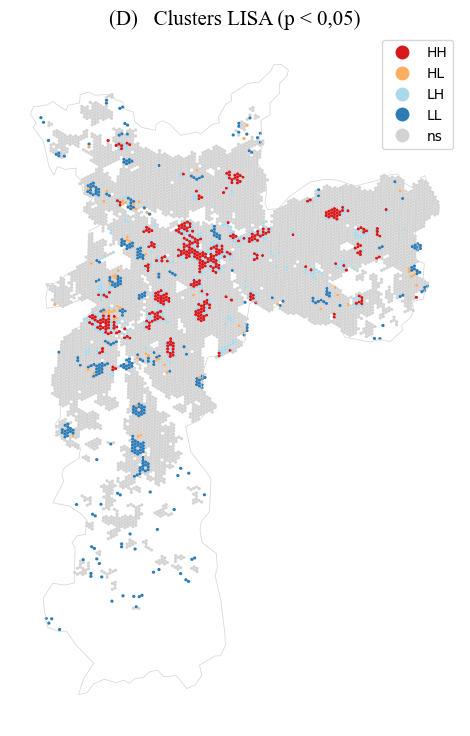

In [6]:
y = housing.delta_housing.values
moranLoc = Moran_Local(y, wHousing2)
coisa, ax = lisa_cluster(moranLoc, housing, p=0.05, figsize=(12, 9))
sp.plot(ax=ax, edgecolor='lightgray', facecolor='none', linewidth=0.5, zorder=1)
ax.set_title("(D)   Clusters LISA (p < 0,05)", fontfamily="Times New Roman", fontsize=15)
plt.savefig(f'./localMoran_deltaHousing2.png', dpi=900)

/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/esda/moran.py:1059: RuntimeWarning: invalid value encountered in divide
  self.z_sim = (self.Is - self.EI_sim) / self.seI_sim


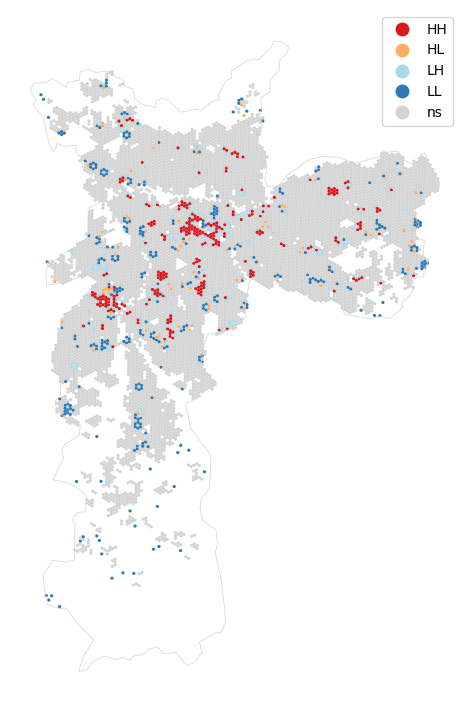

In [16]:
y = housing.delta_housing.values
moranLoc = Moran_Local(y, wHousing)
coisa, ax = lisa_cluster(moranLoc, housing, p=0.05, figsize=(12, 9))
sp.plot(ax=ax, edgecolor='lightgray', facecolor='none', linewidth=0.5, zorder=1)
plt.savefig(f'./localMoran_deltaHousing.png', dpi=900)

In [12]:
housing.sort_values("delta_housing")

,N_HOUSING___13,N_HOUSING___22,geometry,delta_housing
h3_09,,,,
89a81015223ffff,7814,72,"POLYGON ((-46.70423 -23.75522, -46.70316 -23.7...",-7742
89a81039493ffff,5944,2835,"POLYGON ((-46.71512 -23.50316, -46.71406 -23.5...",-3109
89a81005183ffff,3417,919,"POLYGON ((-46.73992 -23.61713, -46.73885 -23.6...",-2498
89a810051d7ffff,2669,173,"POLYGON ((-46.73381 -23.61742, -46.73274 -23.6...",-2496
89a81002c87ffff,1993,184,"POLYGON ((-46.70396 -23.74604, -46.70289 -23.7...",-1809
...,...,...,...,...
89a810055afffff,88,1711,"POLYGON ((-46.74639 -23.62909, -46.74533 -23.6...",1623
89a8100c637ffff,310,1982,"POLYGON ((-46.61604 -23.56766, -46.61497 -23.5...",1672
89a8100c1cfffff,4119,5944,"POLYGON ((-46.64314 -23.55258, -46.64207 -23.5...",1825


In [6]:
jobs13 = pd.read_csv(f"../data/address/destinations__2013.csv", sep=';').rename(columns={"id_hex": "h3_09"})
jobs13 = jobs13.groupby("h3_09").agg({"T001": 'sum'}).reset_index()
jobs22 = pd.read_csv(f"../data/address/destinations__2021.csv", sep=';').rename(columns={"id_hex": "h3_09"})
jobs22 = jobs22.groupby("h3_09").agg({"T001": 'sum'}).reset_index()
jobs = jobs13.merge(jobs22, on="h3_09", suffixes=["___13", "___22"])
del jobs13
del jobs22
jobs = jobs.set_index("h3_09")
jobs = jobs.h3.h3_to_geo_boundary()
jobs["delta_jobs"] = jobs.T001___22 - jobs.T001___13

wJobs = Queen.from_dataframe(jobs)
wJobs2 = higher_order(wJobs, k=2, lower_order=True)

wJobs.transform = 'r'
wJobs2.transform = 'r'


/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_27864/643188617.py:12: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  wJobs = Queen.from_dataframe(jobs)
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 90 disconnected components.
 There are 58 islands with ids: 281, 548, 576, 1039, 1882, 4951, 4956, 4958, 4959, 4964, 4972, 4973, 4974, 4984, 4985, 4986, 4994, 4999, 5012, 5013, 5014, 5040, 5100, 5117, 5118, 5245, 5251, 5257, 5258, 5276, 5285, 5286, 5299, 5308, 5309, 5310, 5311, 5391, 5729, 5796, 5829, 7124, 7651, 7652, 7898, 7975, 8157, 8160, 8161, 8164, 8165, 8167, 8169, 8170, 8171, 8176, 8177, 8179.
  warnings.warn(message)


('WARNING: ', 281, ' is an island (no neighbors)')
('WARNING: ', 548, ' is an island (no neighbors)')
('WARNING: ', 576, ' is an island (no neighbors)')
('WARNING: ', 1039, ' is an island (no neighbors)')
('WARNING: ', 1882, ' is an island (no neighbors)')
('WARNING: ', 4951, ' is an island (no neighbors)')
('WARNING: ', 4956, ' is an island (no neighbors)')
('WARNING: ', 4958, ' is an island (no neighbors)')
('WARNING: ', 4959, ' is an island (no neighbors)')
('WARNING: ', 4964, ' is an island (no neighbors)')
('WARNING: ', 4972, ' is an island (no neighbors)')
('WARNING: ', 4973, ' is an island (no neighbors)')
('WARNING: ', 4974, ' is an island (no neighbors)')
('WARNING: ', 4984, ' is an island (no neighbors)')
('WARNING: ', 4985, ' is an island (no neighbors)')
('WARNING: ', 4986, ' is an island (no neighbors)')
('WARNING: ', 4994, ' is an island (no neighbors)')
('WARNING: ', 4999, ' is an island (no neighbors)')
('WARNING: ', 5012, ' is an island (no neighbors)')
('WARNING: ', 5

/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 108 disconnected components.
 There are 90 islands with ids: 281, 548, 576, 921, 922, 1039, 1882, 4951, 4952, 4953, 4954, 4956, 4958, 4959, 4960, 4961, 4962, 4963, 4964, 4972, 4973, 4974, 4981, 4984, 4985, 4986, 4994, 4999, 5012, 5013, 5014, 5040, 5100, 5117, 5118, 5213, 5214, 5245, 5251, 5257, 5258, 5276, 5283, 5284, 5285, 5286, 5298, 5299, 5308, 5309, 5310, 5311, 5312, 5391, 5403, 5729, 5796, 5815, 5829, 5837, 7124, 7651, 7652, 7898, 7899, 7975, 8157, 8158, 8159, 8160, 8161, 8162, 8163, 8164, 8165, 8166, 8167, 8168, 8169, 8170, 8171, 8172, 8173, 8174, 8175, 8176, 8177, 8178, 8179, 8180.
  warnings.warn(message)


In [1]:
yJobs = jobs.delta_jobs.values
moranLocJobs2 = Moran_Local(yJobs, wJobs2)
#realDeltas = plot_local_autocorrelation(moranLocJobs, jobs, 'delta_jobs')

coisa, ax = lisa_cluster(moranLocJobs2, jobs, p=0.05, figsize=(12, 9))
sp.plot(ax=ax, edgecolor='lightgray', facecolor='none', linewidth=0.5, zorder=1)
ax.set_title("(D)   Clusters LISA (p < 0,05)", fontfamily="Times New Roman", fontsize=15)
plt.savefig(f'./localMoran_deltaJobs2.png', dpi=900)

NameError: name 'jobs' is not defined

/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/esda/moran.py:1059: RuntimeWarning: invalid value encountered in divide
  self.z_sim = (self.Is - self.EI_sim) / self.seI_sim


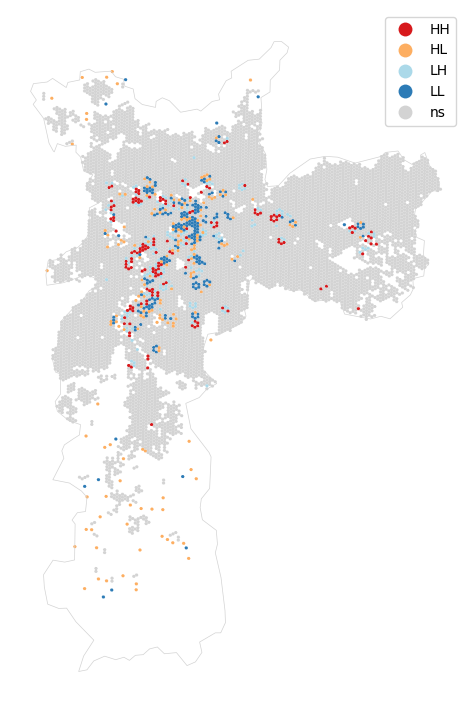

In [10]:
yJobs = jobs.delta_jobs.values
moranLocJobs = Moran_Local(yJobs, wJobs)
#realDeltas = plot_local_autocorrelation(moranLocJobs, jobs, 'delta_jobs')

coisa, ax = lisa_cluster(moranLocJobs, jobs, p=0.05, figsize=(12, 9))
sp.plot(ax=ax, edgecolor='lightgray', facecolor='none', linewidth=0.5, zorder=1)
plt.savefig(f'./localMoran_deltaJobs.png', dpi=900)

In [35]:
access = pd.read_csv("/Users/camillaperotto/Documents/pde-sp/01_AccessPipeline/data/access/real___2013/active.csv", sep=';')

<Axes: ylabel='Frequency'>

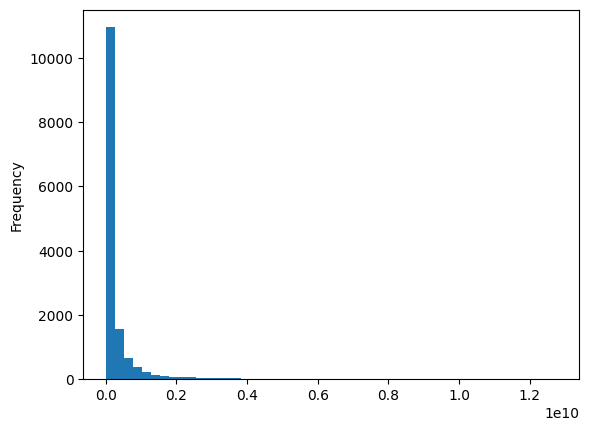

In [37]:
access.pond_T001.plot(kind="hist", bins=50)

In [38]:
import numpy as np

In [ ]:
access = access[access.pond_T001>0]

<Axes: ylabel='Frequency'>

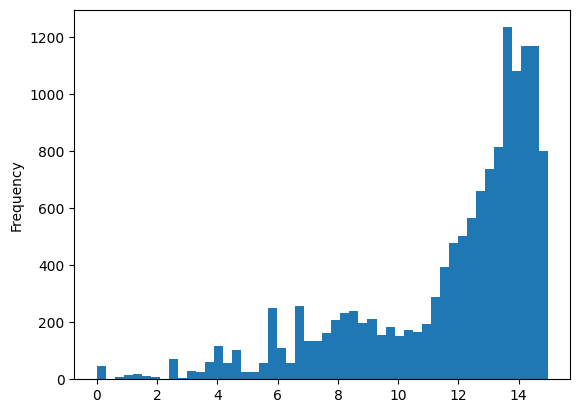

In [46]:
np.log(access[access.T001>0].T001).plot(kind="hist", bins=50)

<Axes: ylabel='Frequency'>

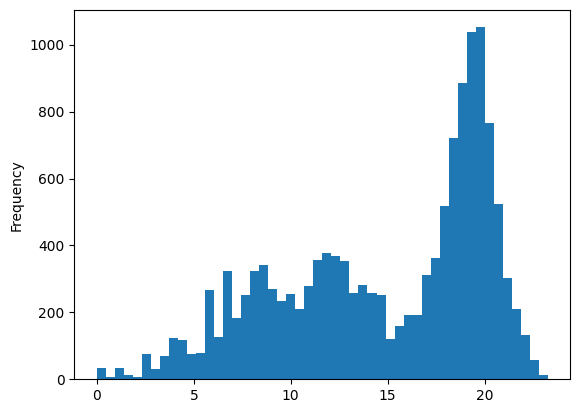

In [40]:
np.log(access[access.pond_T001>0].pond_T001).plot(kind="hist", bins=50)

<Axes: ylabel='Frequency'>

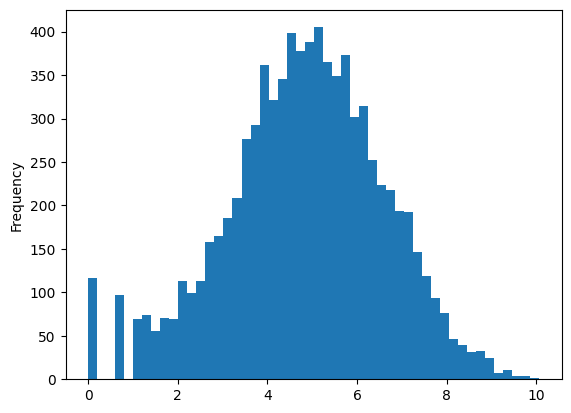

In [45]:
np.log(jobs[jobs.T001___13>0].T001___13).plot(kind="hist", bins=50)

<Axes: ylabel='Frequency'>

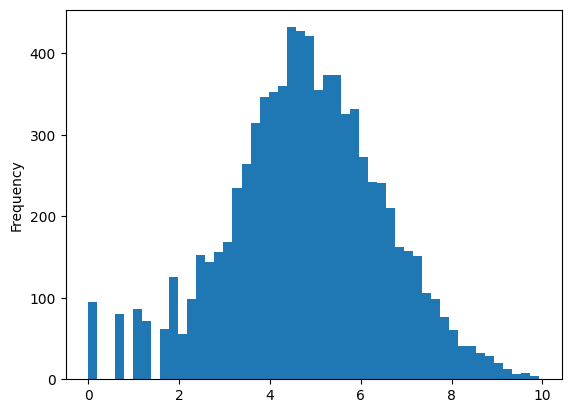

In [47]:
np.log(jobs[jobs.T001___22>0].T001___22).plot(kind="hist", bins=50)

<Axes: ylabel='Frequency'>

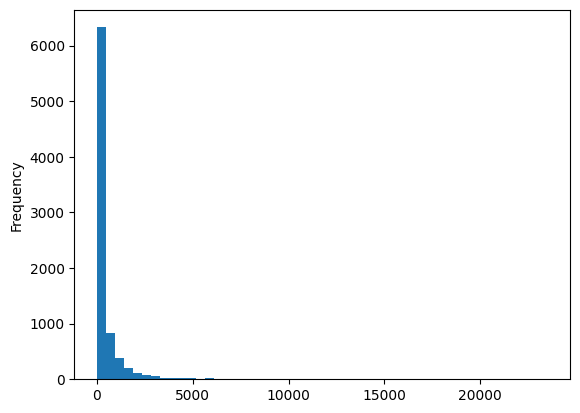

In [44]:
(jobs[jobs.T001___13>0].T001___13).plot(kind="hist", bins=50)